# 01 — Classification Fundamentals: Logistic Regression, k-NN, Trees, Forests, Boosting, SVM, Naive Bayes

**Overview:** binary/multiclass/multilabel framing, then 7 classic classifiers fit on the same
data and compared, plus decision-boundary visualizations.

**Required libraries:** `numpy`, `matplotlib`, `scikit-learn`.

Connects to: `07_regression` (same fit/predict/evaluate pipeline). Leads to:
`02_xgboost_lightgbm.ipynb` and `12_ml_evaluation` (proper classification metrics).

### Abbreviations used in this notebook

| Term | Full form | What it is |
|---|---|---|
| **k-NN** | k-Nearest Neighbors | Predicts from the k closest training points. |
| **SVM** | Support Vector Machine | Classifier that finds the maximum-margin separating boundary. |
| **RBF** | Radial Basis Function | Similarity kernel that decays with distance; common SVM kernel. |
| **XGBoost** | eXtreme Gradient Boosting | Fast, regularised gradient-boosted decision-tree library. |
| **LightGBM** | Light Gradient Boosting Machine | Histogram-based gradient-boosted tree library, optimised for speed and memory. |

## 0. Environment

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification, make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
import time

rng_seed = 42


## 1. Binary vs multiclass vs multilabel

💡 **Intuition:** binary = 2 mutually exclusive classes; multiclass = >2 mutually exclusive
classes; multilabel = each sample can have several labels at once (not mutually exclusive).

In [2]:
# Binary
X_bin, y_bin = make_classification(n_samples=300, n_features=4, n_classes=2, random_state=rng_seed)
print("binary labels:", np.unique(y_bin))

# Multiclass
X_multi, y_multi = make_classification(n_samples=300, n_features=4, n_classes=3,
                                        n_informative=3, n_redundant=0, random_state=rng_seed)
print("multiclass labels:", np.unique(y_multi))

# Multilabel (toy): each sample independently may or may not have each of 2 attributes
multilabel_targets = np.column_stack([
    (X_multi[:, 0] > 0).astype(int),
    (X_multi[:, 1] > 0).astype(int),
])
print("multilabel example row (can be [1,1], [0,0], [1,0], [0,1]):", multilabel_targets[0])
assert multilabel_targets.shape == (300, 2)


binary labels: [0 1]
multiclass labels: [0 1 2]
multilabel example row (can be [1,1], [0,0], [1,0], [0,1]): [0 0]


## 2. A shared dataset + train/test split, and a scaled version for distance-based models

⚠️ **Common Mistake:** k-NN and SVM are distance/margin-based — forgetting to scale features
can make one feature dominate purely due to its numeric range.

In [3]:
X, y = make_classification(n_samples=500, n_features=10, n_informative=6,
                            n_redundant=2, n_classes=2, random_state=rng_seed)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=rng_seed, stratify=y)

scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("train:", X_train.shape, "test:", X_test.shape)
print("class balance (train):", np.bincount(y_train) / len(y_train))


train: (375, 10) test: (125, 10)
class balance (train): [0.49866667 0.50133333]


## 3. Fit all 7 classifiers and compare

In [4]:
models = {
    "LogisticRegression": (LogisticRegression(max_iter=1000), True),
    "kNN (k=5)": (KNeighborsClassifier(n_neighbors=5), True),
    "DecisionTree": (DecisionTreeClassifier(max_depth=5, random_state=rng_seed), False),
    "RandomForest": (RandomForestClassifier(n_estimators=100, random_state=rng_seed), False),
    "GradientBoosting": (GradientBoostingClassifier(random_state=rng_seed), False),
    "SVM (RBF)": (SVC(kernel="rbf"), True),
    "NaiveBayes": (GaussianNB(), False),
}

results = []
for name, (model, needs_scaling) in models.items():
    Xtr = X_train_scaled if needs_scaling else X_train
    Xte = X_test_scaled if needs_scaling else X_test

    start = time.perf_counter()
    model.fit(Xtr, y_train)
    train_time = time.perf_counter() - start

    acc = accuracy_score(y_test, model.predict(Xte))
    results.append((name, acc, train_time))
    print(f"{name:20s} test accuracy={acc:.3f}  train_time={train_time*1000:.1f}ms")

accuracies = [r[1] for r in results]
assert all(a > 0.5 for a in accuracies)   # all should beat random guessing on this separable data


LogisticRegression   test accuracy=0.880  train_time=11.7ms
kNN (k=5)            test accuracy=0.904  train_time=1.2ms
DecisionTree         test accuracy=0.864  train_time=1.4ms
RandomForest         test accuracy=0.896  train_time=50.2ms
GradientBoosting     test accuracy=0.872  train_time=54.1ms
SVM (RBF)            test accuracy=0.936  train_time=1.7ms
NaiveBayes           test accuracy=0.824  train_time=0.4ms


## 4. Decision boundaries on a 2D toy dataset

🎯 **Interview Tip:** visualizing decision boundaries makes the qualitative difference between
"linear" models (logistic regression, linear SVM) and "local/non-linear" models (k-NN, trees)
immediately obvious.

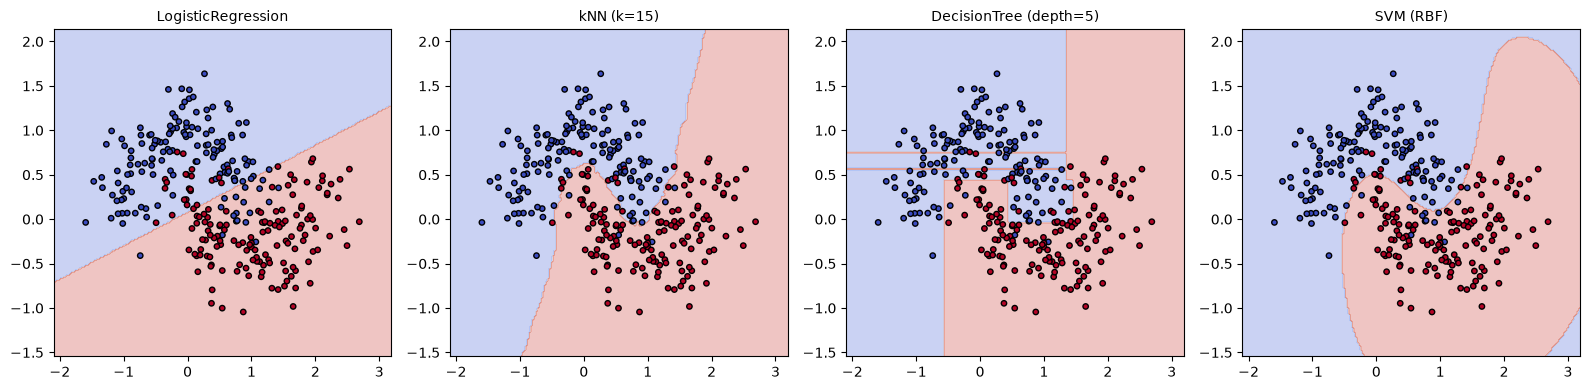

Note how logistic regression draws a straight line, while kNN and the decision tree carve out jagged, local regions that follow the moon shapes more closely.


In [5]:
X_2d, y_2d = make_moons(n_samples=300, noise=0.25, random_state=rng_seed)

boundary_models = {
    "LogisticRegression": LogisticRegression(),
    "kNN (k=15)": KNeighborsClassifier(n_neighbors=15),
    "DecisionTree (depth=5)": DecisionTreeClassifier(max_depth=5, random_state=rng_seed),
    "SVM (RBF)": SVC(kernel="rbf"),
}

xx, yy = np.meshgrid(np.linspace(X_2d[:, 0].min() - 0.5, X_2d[:, 0].max() + 0.5, 200),
                      np.linspace(X_2d[:, 1].min() - 0.5, X_2d[:, 1].max() + 0.5, 200))
grid = np.column_stack([xx.ravel(), yy.ravel()])

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (name, model) in zip(axes, boundary_models.items()):
    model.fit(X_2d, y_2d)
    preds = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, preds, alpha=0.3, cmap="coolwarm")
    ax.scatter(X_2d[:, 0], X_2d[:, 1], c=y_2d, cmap="coolwarm", edgecolors="k", s=15)
    ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()

print("Note how logistic regression draws a straight line, while kNN and the decision tree "
      "carve out jagged, local regions that follow the moon shapes more closely.")


## 5. Connection to what's next

`02_xgboost_lightgbm.ipynb` benchmarks `GradientBoostingClassifier` from this notebook against
dedicated XGBoost and LightGBM implementations on the same shared dataset.

## 6. Interview questions
1. Why does logistic regression draw a straight decision boundary while k-NN and decision trees don't?
2. What's the effect of increasing `k` in k-NN on the decision boundary's smoothness?
3. Why is `max_depth` such an important hyperparameter for a single decision tree?
4. Why does Naive Bayes often train and predict faster than the other models here?
5. When would an RBF-kernel SVM be preferable to a linear model?

## 7. Exercises
1. Re-run the 7-model comparison on a noisier dataset (`make_classification(..., flip_y=0.1)`) and see which models degrade most.
2. Plot train vs test accuracy for `DecisionTreeClassifier` as `max_depth` increases from 1 to 20.
3. Repeat the decision-boundary visualization with `k=1` for k-NN and describe why the boundary looks noisier.

## 8. Summary

✅ Seven classic classifiers, one shared evaluation pipeline: linear (logistic regression),
instance-based (k-NN), tree-based (decision tree/random forest/gradient boosting), margin-based
(SVM), and probabilistic (Naive Bayes) each make different tradeoffs between interpretability,
speed, and the shape of decision boundary they can represent. Next:
`02_xgboost_lightgbm.ipynb`.